# Задача 4.11 — Встреча $n$ лиц

---

## 1. Условие

$n$ лиц договорились о встрече между 10 и 11 часами, причём договорились ждать друг друга не более $60q$ минут ($q < 1$). Считая моменты прихода «наудачу» в пределах часа, докажите, что вероятность встречи

$$
P_n = n q^{n-1} - (n-1)q^n.
$$

Проверьте формулу для $n = 2$ и $n = 3$. Для $n = 3$ найдите также вероятность того, что встреча состоится по крайней мере у двух лиц.

---

## 2. Теоретическая часть

Пусть $x_1, \dots, x_n \in [0, 1]$ — моменты прихода (в долях часа). Все вместе встречаются, если

$$
\max_i x_i - \min_i x_i \le q.
$$

Это событие «размах выборки не превосходит $q$». Вероятность:

$$
P_n = P(\max x_i - \min x_i \le q)
= n q^{n-1} - (n-1) q^n.
$$

### Проверка

- $n = 2$: $P_2 = 2q - q^2 = 1 - (1-q)^2$ — классическая формула встречи двух лиц.
- $n = 3$: $P_3 = 3q^2 - 2q^3$.

### Для $n = 3$, «по крайней мере двое встретились»

Событие «хотя бы одна пара сблизилась не более чем на $q$». Дополнение — все попарные расстояния $> q$, что при трёх точках на отрезке длины 1 возможно только если точки расположены в порядке с зазорами $> q$:

$$
P(\text{все пары далеки}) = P(x_{(3)} - x_{(1)} > q \text{ и зазоры } > q)
= (1 - 2q)^2 \quad \text{(при } 2q \le 1\text{)}.
$$

Тогда

$$
P(\text{хотя бы двое}) = 1 - (1 - 2q)^2 = 4q(1-q).
$$

---

## 3. Решение

n=2: P_n(q=0.25) = 0.437500
n=3: P_n(q=0.25) = 0.156250
n=4: P_n(q=0.25) = 0.050781

n=3: P(все) теор. = 0.156250, модел. = 0.156860
n=3: P(хотя бы двое) теор. = 0.750000, модел. = 0.874213


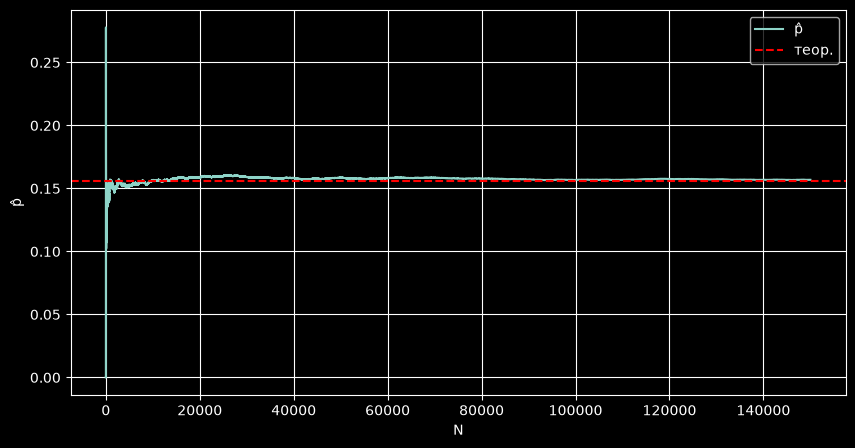

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def P_n(n, q):
    return n*q**(n-1) - (n-1)*q**n

# Проверки
for n in [2, 3, 4]:
    print(f"n={n}: P_n(q=0.25) = {P_n(n, 0.25):.6f}")

# Моделирование для n=3
N = 150_000
q = 0.25
rng = np.random.default_rng(seed=10)
X = rng.uniform(0, 1, (N, 3))
all_meet = (X.max(axis=1) - X.min(axis=1)) <= q
# хотя бы одна пара
pair_meet = np.zeros(N, dtype=bool)
for i in range(3):
    for j in range(i+1, 3):
        pair_meet |= np.abs(X[:, i] - X[:, j]) <= q

print(f"\nn=3: P(все) теор. = {P_n(3, q):.6f}, модел. = {all_meet.mean():.6f}")
print(f"n=3: P(хотя бы двое) теор. = {4*q*(1-q):.6f}, модел. = {pair_meet.mean():.6f}")

freq = np.cumsum(all_meet) / np.arange(1, N+1)
plt.figure(figsize=(10, 5))
plt.plot(freq)
plt.axhline(P_n(3, q), color="r", ls="--")
plt.xlabel("N"); plt.ylabel("p̂"); plt.legend(["p̂", "теор."]); plt.grid(True)
plt.show()